In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 04 — Machine learning (validation 2021–22)
Random forest, boosting, SVM, blends, and whether updating weights as results arrive helps. Report: `docs/phase5_ml.md`.

In [2]:
table("phase5_ml_val.csv", index_col=0).drop(columns=["f1_draw"]).round(4)

,log_loss,brier,rps,accuracy,f1_macro,ece,fit_seconds,cv_log_loss
model,,,,,,,,
Class frequency (naive),1.0704,0.6474,0.2298,0.4423,0.2045,NaN,NaN,NaN
Elo (LogReg),0.9962,0.5940,0.2038,0.5248,0.3879,0.0146,NaN,NaN
LogReg: all features,0.9859,0.5868,0.2009,0.5303,0.3985,0.0190,NaN,NaN
Random Forest,0.9894,0.5893,0.2018,0.5325,0.3940,0.0219,292.0,0.9784
Gradient Boosting,0.9888,0.5890,0.2016,0.5311,0.3936,0.0224,117.0,0.9799
SVM (RBF),1.0098,0.6038,0.2069,0.5193,0.3767,0.0461,141.0,1.0034
Bookmaker Bet365 (reference),0.9781,0.5819,0.1983,0.5338,0.3976,0.0171,NaN,NaN
Blend: LogReg + Gradient Boosting,0.9856,0.5869,0.2008,0.5327,0.3972,0.0217,NaN,NaN


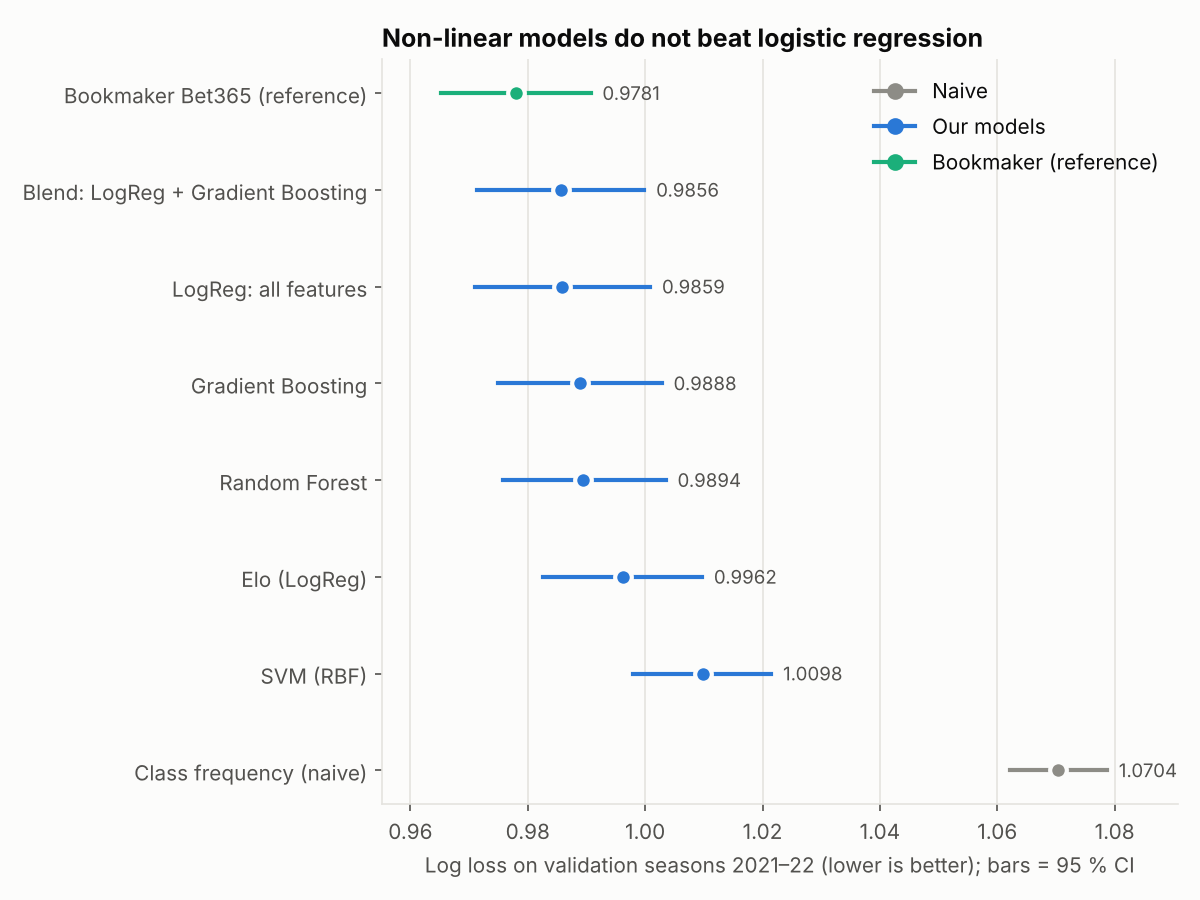

In [3]:
show("phase5_logloss.png", 760)

### Hyper-parameter search (time-ordered CV on the training seasons)

In [4]:
t = table("phase5_tuning.csv")
t.groupby("model").agg(configs=("cv_log_loss", "size"), best=("cv_log_loss", "min"), median=("cv_log_loss", "median"),
                       worst=("cv_log_loss", "max")).round(4)

,configs,best,median,worst
model,,,,
Gradient Boosting,20,0.9799,0.9941,1.2026
Random Forest,12,0.9784,0.9791,0.9825
SVM (RBF),4,1.0034,1.0075,1.0106


In [5]:
t.groupby("model").head(2)[["model", "cv_log_loss", "params"]].round(4).to_string(max_colwidth=130)

"                model  cv_log_loss                                                                                                                             params\n0       Random Forest       0.9784  {'randomforestclassifier__n_estimators': 400, 'randomforestclassifier__min_samples_leaf': 10, 'randomforestclassifier__max_fea...\n1       Random Forest       0.9786  {'randomforestclassifier__n_estimators': 200, 'randomforestclassifier__min_samples_leaf': 25, 'randomforestclassifier__max_fea...\n12  Gradient Boosting       0.9799  {'l2_regularization': 1.0, 'learning_rate': np.float64(0.029358276900252726), 'max_depth': 2, 'max_iter': 100, 'max_leaf_nodes...\n13  Gradient Boosting       0.9801  {'l2_regularization': 0.0, 'learning_rate': np.float64(0.054897127184964416), 'max_depth': 2, 'max_iter': 50, 'max_leaf_nodes'...\n32          SVM (RBF)       1.0034                                                                                                {'svc__C': 0.3, 'svc__gamma': 0.02

### Static vs weekly refit vs online gradient updates

In [6]:
display(table("phase5_online_val.csv", index_col=0).round(4)); display(table("phase5_online_val_bootstrap.csv").round(5))

,log_loss,brier,rps,accuracy,f1_macro,f1_draw,ece
regime,,,,,,,
static,0.9859,0.5868,0.2009,0.5303,0.3985,0.0086,0.0190
online,0.9858,0.5868,0.2008,0.5297,0.3979,0.0086,0.0171
refit,0.9854,0.5865,0.2007,0.5305,0.3994,0.0129,0.0191


,regime,vs,diff,ci_low,ci_high,significant
0,refit,static,-0.00050,-0.00122,0.00022,False
1,online,static,-0.00005,-0.00056,0.00046,False
2,online,refit,0.00045,-0.00017,0.00107,False


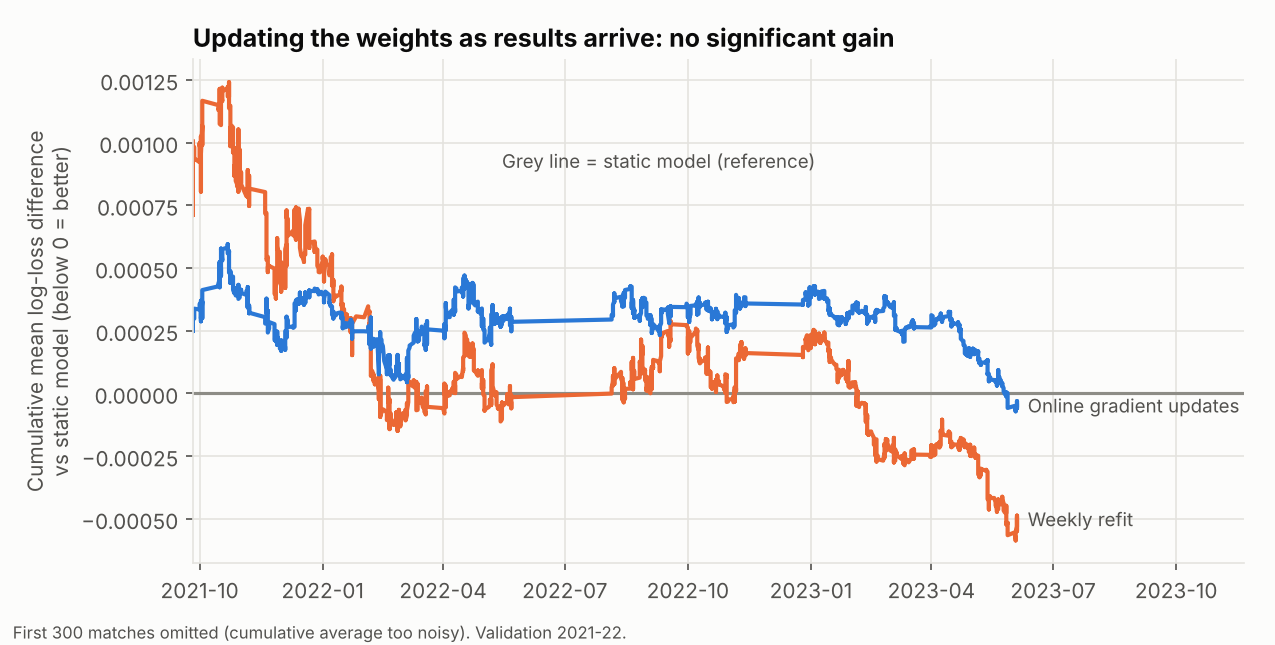

In [7]:
show("phase5_online.png")